# Student Performance Factors Dataset
### Author: Vazil


In [89]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import os
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

 Imported pandas for data manipulation and NumPy for numerical operations.

In [90]:
print(os.getcwd())
print(os.listdir())

d:\python\Student Performance Factors Dataset\notebooks
['student_performance.ipynb']


In [91]:
df=pd.read_csv(r"../data/StudentPerformanceFactors.csv")

 Loaded the dataset from the data folder using a relative path. Relative paths make the project portable so it works on other computers with the same folder structure.

In [92]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


Displayed the first five rows to verify that the dataset loaded correctly and to understand its structure.

In [93]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

Examined the dataset's columns, data types, and missing values to understand what preprocessing would be required.

In [94]:
df.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

in 3 columns have missing values

In [95]:
df.duplicated().sum()

0

0 duplicates entries

In [96]:
print(df['Distance_from_Home'].value_counts(dropna=False),'\n')
print(df['Parental_Education_Level'].value_counts(dropna=False),'\n')
print(df['Teacher_Quality'].value_counts(dropna=False))

Distance_from_Home
Near        3884
Moderate    1998
Far          658
NaN           67
Name: count, dtype: int64 

Parental_Education_Level
High School     3223
College         1989
Postgraduate    1305
NaN               90
Name: count, dtype: int64 

Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64


The three columns contain only about 1% missing values. Since they are categorical features and the amount of missing data is very small, I chose to replace the missing values with the mode (most frequent category). This preserves all records while keeping the preprocessing simple and appropriate.

In [97]:
for col in ["Distance_from_Home", "Parental_Education_Level", "Teacher_Quality"]:
    df[col] = df[col].fillna(df[col].mode()[0])

In [98]:
df.shape

(6607, 20)

In [99]:
df.isna().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [100]:
objects = df.select_dtypes(include=["object"]).columns

for col in objects:
    print(f"{col}: {df[col].nunique()} unique values")
    print(df[col].unique())
    print("-" * 50)

Parental_Involvement: 3 unique values
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
--------------------------------------------------
Access_to_Resources: 3 unique values
<ArrowStringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str
--------------------------------------------------
Extracurricular_Activities: 2 unique values
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
--------------------------------------------------
Motivation_Level: 3 unique values
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
--------------------------------------------------
Internet_Access: 2 unique values
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
--------------------------------------------------
Family_Income: 3 unique values
<ArrowStringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
--------------------------------------------------
Teacher_Quality: 3 unique values
<ArrowStringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

C:\Users\user\AppData\Local\Temp\ipykernel_16284\1990843583.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  objects = df.select_dtypes(include=["object"]).columns


In [101]:
encoder = LabelEncoder()

binary_cols = []
onehot_cols = []

for col in df.select_dtypes(include="object").columns:
    if df[col].nunique() == 2:
        binary_cols.append(col)
    else:
        onehot_cols.append(col)

C:\Users\user\AppData\Local\Temp\ipykernel_16284\3936279778.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


here we collect the columns have 2 unique into a list the remaining in another list 

In [102]:
for col in binary_cols:
    df[col] = encoder.fit_transform(df[col])
    
df = pd.get_dummies(df, columns=onehot_cols, drop_first=True)

here change the columns have natural orders that change to one hot encoder the remaining into label encoder

In [103]:
df.dtypes

Hours_Studied                            int64
Attendance                               int64
Extracurricular_Activities               int32
Sleep_Hours                              int64
Previous_Scores                          int64
Internet_Access                          int32
Tutoring_Sessions                        int64
School_Type                              int32
Physical_Activity                        int64
Learning_Disabilities                    int32
Gender                                   int32
Exam_Score                               int64
Parental_Involvement_Low                  bool
Parental_Involvement_Medium               bool
Access_to_Resources_Low                   bool
Access_to_Resources_Medium                bool
Motivation_Level_Low                      bool
Motivation_Level_Medium                   bool
Family_Income_Low                         bool
Family_Income_Medium                      bool
Teacher_Quality_Low                       bool
Teacher_Quali

so every columns changes to object -> integer / bool

In [104]:
bool_columns = df.select_dtypes(include=["bool"]).columns
print("Boolean columns:", bool_columns)
df[bool_columns] = df[bool_columns].astype(int)

Boolean columns: Index(['Parental_Involvement_Low', 'Parental_Involvement_Medium',
       'Access_to_Resources_Low', 'Access_to_Resources_Medium',
       'Motivation_Level_Low', 'Motivation_Level_Medium', 'Family_Income_Low',
       'Family_Income_Medium', 'Teacher_Quality_Low', 'Teacher_Quality_Medium',
       'Peer_Influence_Neutral', 'Peer_Influence_Positive',
       'Parental_Education_Level_High School',
       'Parental_Education_Level_Postgraduate', 'Distance_from_Home_Moderate',
       'Distance_from_Home_Near'],
      dtype='str')


change bools into int 

In [105]:
df.describe()

,Hours_Studied,Attendance,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Internet_Access,Tutoring_Sessions,School_Type,Physical_Activity,Learning_Disabilities,...,Family_Income_Low,Family_Income_Medium,Teacher_Quality_Low,Teacher_Quality_Medium,Peer_Influence_Neutral,Peer_Influence_Positive,Parental_Education_Level_High School,Parental_Education_Level_Postgraduate,Distance_from_Home_Moderate,Distance_from_Home_Near
count,6607.000000,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,...,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,0.596035,7.02906,75.070531,0.924474,1.493719,0.695929,2.967610,0.105191,...,0.404420,0.403511,0.099440,0.605873,0.392311,0.399273,0.501438,0.197518,0.302407,0.598002
std,5.990594,11.547475,0.490728,1.46812,14.399784,0.264258,1.230570,0.460048,1.031231,0.306823,...,0.490817,0.490639,0.299275,0.488699,0.488302,0.489786,0.500036,0.398156,0.459335,0.490339
min,1.000000,60.000000,0.000000,4.00000,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,70.000000,0.000000,6.00000,63.000000,1.000000,1.000000,0.000000,2.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,20.000000,80.000000,1.000000,7.00000,75.000000,1.000000,1.000000,1.000000,3.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000
75%,24.000000,90.000000,1.000000,8.00000,88.000000,1.000000,2.000000,1.000000,4.000000,0.000000,...,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
max,44.000000,100.000000,1.000000,10.00000,100.000000,1.000000,8.000000,1.000000,6.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


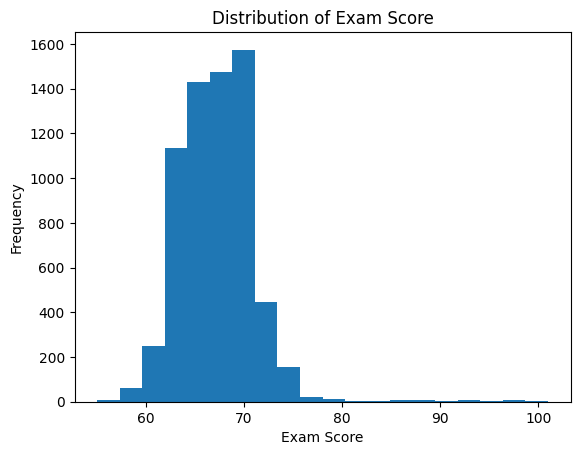

In [106]:
plt.hist(df["Exam_Score"], bins=20)
plt.title("Distribution of Exam Score")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.show()

The distribution of exam scores is concentrated between 63 and 70. Most students achieved average scores, while only a small number scored exceptionally high or low.

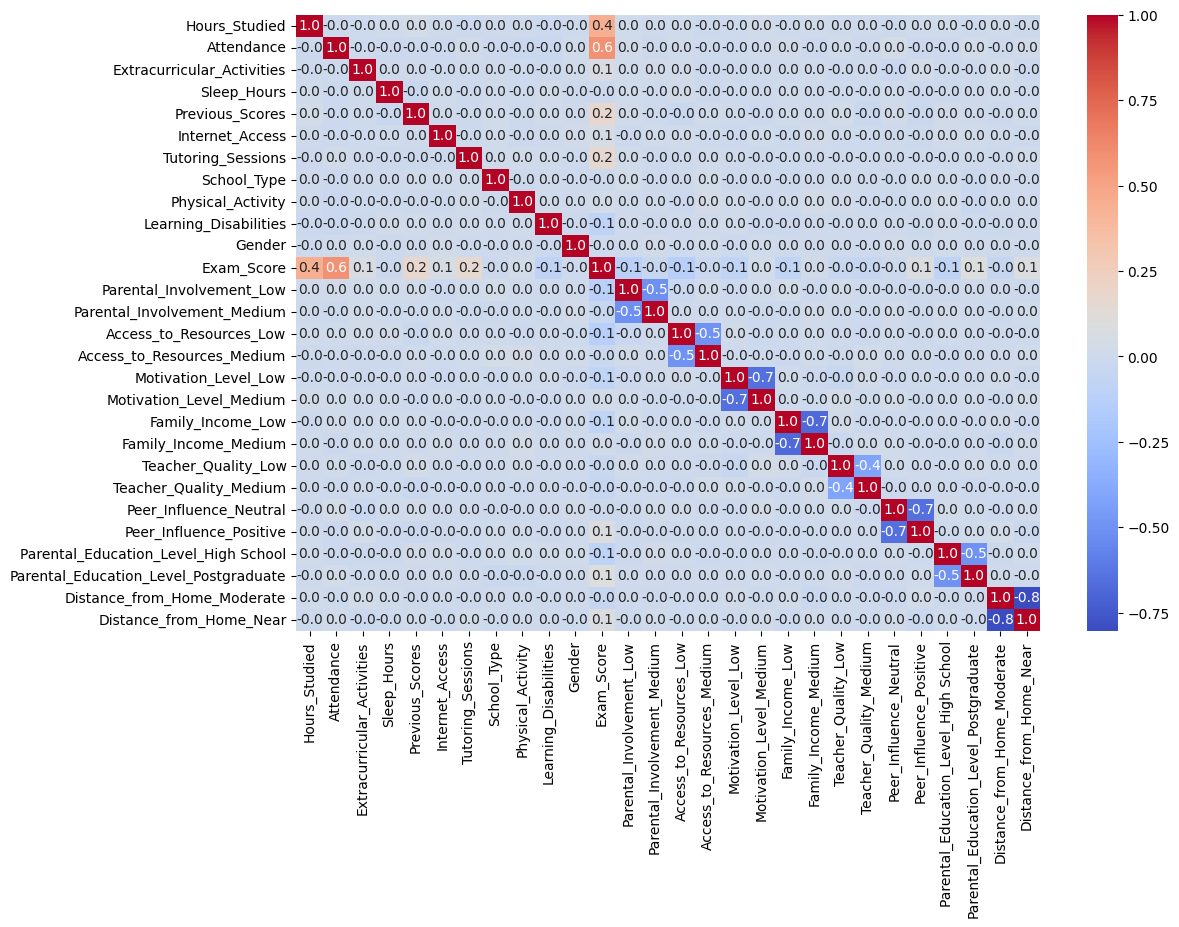

In [107]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm", annot=True, fmt=".1f")
plt.show()

<Axes: xlabel='Hours_Studied', ylabel='Exam_Score'>

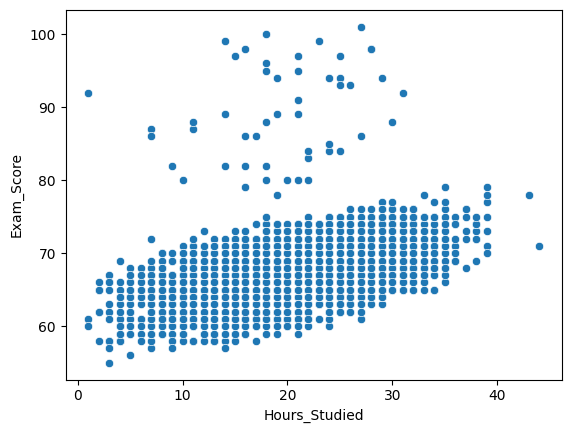

In [108]:
sns.scatterplot(
    x="Hours_Studied",
    y="Exam_Score",
    data=df
)

There is a positive relationship between study hours and exam score, but it is not perfect. Other factors also influence student performance.

<Axes: ylabel='Hours_Studied'>

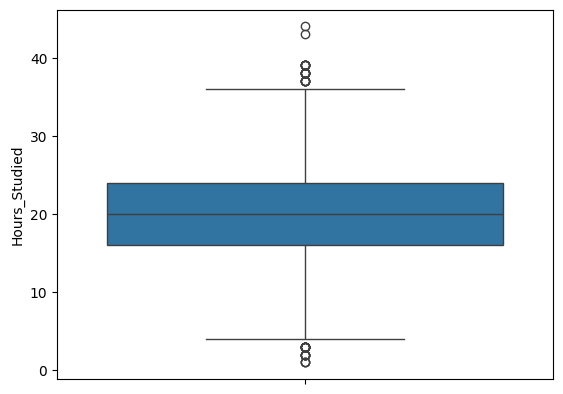

In [109]:
sns.boxplot(y=df["Hours_Studied"])

In [110]:
df.corr(numeric_only=True)["Exam_Score"].sort_values(ascending=False)

Exam_Score                               1.000000
Attendance                               0.581072
Hours_Studied                            0.445455
Previous_Scores                          0.175079
Tutoring_Sessions                        0.156525
Parental_Education_Level_Postgraduate    0.093764
Peer_Influence_Positive                  0.081217
Distance_from_Home_Near                  0.080933
Extracurricular_Activities               0.064382
Internet_Access                          0.051475
Physical_Activity                        0.027824
Motivation_Level_Medium                  0.024771
Family_Income_Medium                     0.020995
Gender                                  -0.002032
Peer_Influence_Neutral                  -0.007795
School_Type                             -0.008844
Sleep_Hours                             -0.017022
Access_to_Resources_Medium              -0.026158
Parental_Involvement_Medium             -0.035978
Teacher_Quality_Low                     -0.041192


Correlation analysis shows that Attendance (0.581) and Hours_Studied (0.445) have a moderate positive relationship with the exam score, indicating that students with higher attendance and more study hours generally achieve better scores. Previous_Scores (0.175) and Tutoring_Sessions (0.156) have weak positive correlations, while most other features exhibit weak or negligible linear relationships with the target variable.

In [111]:
X=df.drop("Exam_Score", axis=1)
y=df["Exam_Score"]

In [112]:
feature_names = X.columns.tolist()

joblib.dump(feature_names, "../models/features.pkl")

['../models/features.pkl']

In [113]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [114]:
scaler = StandardScaler()
x_train= scaler.fit_transform(x_train)
x_test= scaler.transform(x_test)

In [115]:
lr1=LinearRegression()
dt=DecisionTreeRegressor(random_state=42)
rf=RandomForestRegressor(n_estimators=100,max_depth=10,random_state=42)

In [116]:
lr1.fit(x_train, y_train)
dt.fit(x_train, y_train)
rf.fit(x_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [117]:
lr_pred = lr1.predict(x_test)

dt_pred = dt.predict(x_test)

rf_pred = rf.predict(x_test)

In [118]:
models=[lr1, dt, rf]
for model in models:
    print(model, "R^2 Score:", r2_score(y_test, model.predict(x_test)),'\n', "MSE:", mean_squared_error(y_test, model.predict(x_test)))
    print("-" * 50)

LinearRegression() R^2 Score: 0.773581216612856 
 MSE: 3.1109875853299354
--------------------------------------------------
DecisionTreeRegressor(random_state=42) R^2 Score: -0.13985855292710436 
 MSE: 15.661623802319717
--------------------------------------------------
RandomForestRegressor(max_depth=10, random_state=42) R^2 Score: 0.6304353847111825 
 MSE: 5.077807207253216
--------------------------------------------------


In [119]:
joblib.dump(lr1,"../models/linear_regression_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

['../models/scaler.pkl']

In [120]:
df.corr(numeric_only=True)["Exam_Score"].sort_values(ascending=False)

Exam_Score                               1.000000
Attendance                               0.581072
Hours_Studied                            0.445455
Previous_Scores                          0.175079
Tutoring_Sessions                        0.156525
Parental_Education_Level_Postgraduate    0.093764
Peer_Influence_Positive                  0.081217
Distance_from_Home_Near                  0.080933
Extracurricular_Activities               0.064382
Internet_Access                          0.051475
Physical_Activity                        0.027824
Motivation_Level_Medium                  0.024771
Family_Income_Medium                     0.020995
Gender                                  -0.002032
Peer_Influence_Neutral                  -0.007795
School_Type                             -0.008844
Sleep_Hours                             -0.017022
Access_to_Resources_Medium              -0.026158
Parental_Involvement_Medium             -0.035978
Teacher_Quality_Low                     -0.041192


In [121]:
import pandas as pd

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance.sort_values(ascending=False)

Attendance                               0.407625
Hours_Studied                            0.259168
Previous_Scores                          0.086438
Tutoring_Sessions                        0.037718
Physical_Activity                        0.022647
Sleep_Hours                              0.022622
Parental_Involvement_Low                 0.019408
Access_to_Resources_Low                  0.016987
Parental_Education_Level_Postgraduate    0.010391
Learning_Disabilities                    0.009355
Access_to_Resources_Medium               0.009138
Distance_from_Home_Near                  0.008080
Peer_Influence_Positive                  0.008065
Parental_Education_Level_High School     0.008022
Family_Income_Low                        0.007016
Gender                                   0.006986
Parental_Involvement_Medium              0.006568
Teacher_Quality_Medium                   0.006535
School_Type                              0.006356
Extracurricular_Activities               0.006334


In [122]:
drop_cols = [
    "Teacher_Quality_Low",
    "Peer_Influence_Neutral",
    "Internet_Access",
    "Motivation_Level_Medium"
]

X_new = X.drop(columns=drop_cols)

## Feature Selection

Feature importance from the Random Forest model was used to identify features with the least contribution to prediction.

Initially, the model was trained using all features and achieved an R² score of **0.6393**.

The following low-importance features were removed:

- Teacher_Quality_Low
- Peer_Influence_Neutral
- Internet_Access
- Motivation_Level_Medium

After retraining the model, the R² score improved to **0.6504**. Additional feature removal reduced the model's performance, so these four features were selected for removal in the final model.

In [123]:
X_train, X_test, y_train, y_test = train_test_split(
    X_new,
    y,
    test_size=0.2,
    random_state=42
)

In [124]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [125]:
lr=LinearRegression()
dt=DecisionTreeRegressor(random_state=42)
rf=RandomForestRegressor(n_estimators=100,max_depth=10,random_state=42)

In [126]:
lr.fit(X_train, y_train)
dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [127]:
y_pred = rf.predict(X_test)
r2 = r2_score(y_test, y_pred)

print(r2)

0.642977587656045


In [128]:
models=[lr, dt, rf]
for model in models:
    print(model, "R^2 Score:", r2_score(y_test, model.predict(X_test)),'\n', "MSE:", mean_squared_error(y_test, model.predict(X_test)))
    print("-" * 50)

LinearRegression() R^2 Score: 0.7562313315613336 
 MSE: 3.445687795040853
--------------------------------------------------
DecisionTreeRegressor(random_state=42) R^2 Score: 0.031764306798512276 
 MSE: 13.68608169440242
--------------------------------------------------
RandomForestRegressor(max_depth=10, random_state=42) R^2 Score: 0.642977587656045 
 MSE: 5.0465376729870055
--------------------------------------------------


In [129]:
import joblib

feature_names = joblib.load("../models/features.pkl")

for col in feature_names:
    print(col)

Hours_Studied
Attendance
Extracurricular_Activities
Sleep_Hours
Previous_Scores
Internet_Access
Tutoring_Sessions
School_Type
Physical_Activity
Learning_Disabilities
Gender
Parental_Involvement_Low
Parental_Involvement_Medium
Access_to_Resources_Low
Access_to_Resources_Medium
Motivation_Level_Low
Motivation_Level_Medium
Family_Income_Low
Family_Income_Medium
Teacher_Quality_Low
Teacher_Quality_Medium
Peer_Influence_Neutral
Peer_Influence_Positive
Parental_Education_Level_High School
Parental_Education_Level_Postgraduate
Distance_from_Home_Moderate
Distance_from_Home_Near
